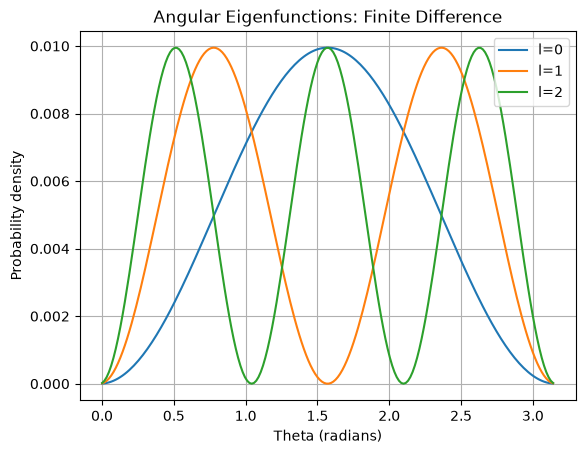

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

N = 200
theta = np.linspace(0.001, np.pi-0.001, N)
h = theta[1] - theta[0]

H = np.zeros((N, N))

for i in range(N):
    H[i, i] = 2/h**2
    if i > 0:
        H[i, i-1] = -1/h**2
    if i < N-1:
        H[i, i+1] = -1/h**2

m = 0
for i in range(N):
    H[i, i] += m**2 / np.sin(theta[i])**2

E, psi = np.linalg.eigh(H)

plt.plot(theta, psi[:, 0]**2, label="l=0")
plt.plot(theta, psi[:, 1]**2, label="l=1")
plt.plot(theta, psi[:, 2]**2, label="l=2")

plt.xlabel("Theta (radians)")
plt.ylabel("Probability density")
plt.title("Angular Eigenfunctions: Finite Difference")
plt.legend()
plt.grid()
plt.show()





Bound-state energies:
[-8.54118978 -4.44593283]


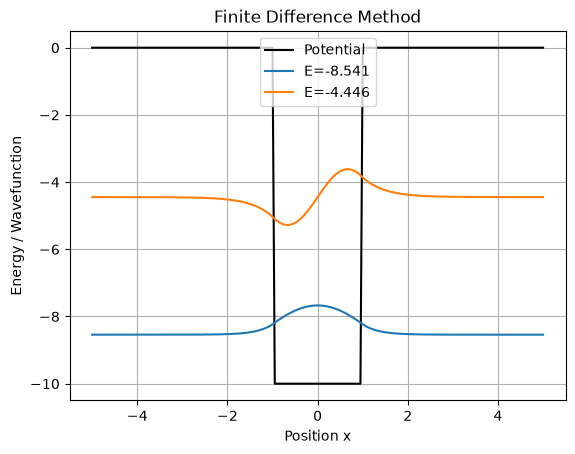

In [7]:

import numpy as np
import matplotlib.pyplot as plt

a = 1.0
V0 = 10.0
L = 5.0
N = 201

x = np.linspace(-L, L, N)
dx = x[1] - x[0]

V = np.zeros(N)
V[np.abs(x) < a] = -V0

H = np.zeros((N-2, N-2))

for i in range(N-2):
    H[i, i] = 2/dx**2 + V[i+1]
    if i > 0:
        H[i, i-1] = -1/dx**2
    if i < N-3:
        H[i, i+1] = -1/dx**2

E, psi = np.linalg.eigh(H)
bound = np.where((E > -V0) & (E < 0))[0]

print("Bound-state energies:")
print(E[bound])

plt.plot(x, V, 'k', label="Potential")

for j in bound[:3]:
    y = np.zeros(N)
    y[1:-1] = psi[:, j]
    y /= np.sqrt(np.sum(y**2)*dx)
    plt.plot(x, E[j] + y, label=f"E={E[j]:.3f}")

plt.xlabel("Position x")
plt.ylabel("Energy / Wavefunction")
plt.title("Finite Difference Method")
plt.legend()
plt.grid()
plt.show()


Even state energy = -8.596396396396397
Odd state energy = -4.6203803803803805


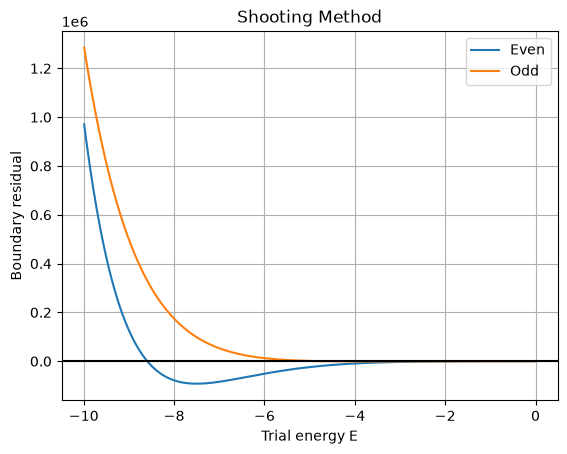

In [9]:

import numpy as np
import matplotlib.pyplot as plt

a = 1.0
V0 = 10.0
L = 5.0
N = 2001

x = np.linspace(0, L, N)
dx = x[1] - x[0]

def shoot(E, odd):
    if odd:
        psi, dpsi = 0.0, 1.0
    else:
        psi, dpsi = 1.0, 0.0

    for i in range(N-1):
        V = -V0 if x[i] < a else 0.0

        def f(y):
            return np.array([y[1], (V-E)*y[0]])

        y = np.array([psi, dpsi])
        k1 = f(y)
        k2 = f(y + dx*k1/2)
        k3 = f(y + dx*k2/2)
        k4 = f(y + dx*k3)

        y += dx*(k1 + 2*k2 + 2*k3 + k4)/6
        psi, dpsi = y

    return dpsi + np.sqrt(-E)*psi

energies = np.linspace(-V0+0.01, -0.01, 1000)

for odd in [False, True]:
    values = np.array([shoot(E, odd) for E in energies])

    for i in range(len(energies)-1):
        if values[i]*values[i+1] < 0:
            E = (energies[i] + energies[i+1])/2
            print("Odd" if odd else "Even",
                  "state energy =", E)

    plt.plot(energies, values,
             label="Odd" if odd else "Even")

plt.axhline(0, color="black")
plt.xlabel("Trial energy E")
plt.ylabel("Boundary residual")
plt.title("Shooting Method")
plt.legend()
plt.grid()
plt.show()
